# Import Libraries

In [493]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression,LassoCV
from sklearn.metrics import accuracy_score,mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

# Μέρος 1 – Λογιστική Παλινδρόμηση

# Load Dataset

Το σύνολο δεδομένων αποτελείται από 768 εγγραφές. Για κάθε εγγραφή έχουν  καταγραφεί 9 χαρακτηριστικά. Στο παρακάτω πίνακα φαίνονται οι πρώτες πληροφορίες για το σύνολο δεδομένων μας.

In [494]:
df = pd.read_csv('diabetes.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Τα χαρακτηριστικά και ο τύπος των δεοδομένων που έχουν καταχωρηθεί, είναι τα ακόλουθα:


*   **Pregnancies** (int64): Εγκυμοσύνες
*   **Glucose** (int64): Επίπεδα γλυκόζης              
*   **BloodPressure** (int64): Αρτηριακή πίεση            
*   **SkinThickness** (int64): Πάχος δέρματος         
*   **Insulin** (int64): Επίπεδα ινσουλίνης                 
*   **BMI** (float64): Δείκτης μάζα σώματος (ΔΜΣ)                     
*   **DiabetesPedigreeFunctio**n(float64): Δείκτης γεννετικής προδιάθεσης. Ο αριθμός αυτός εκφράζει την εκδήλωση- ιστορικότητα της νόσου στην οικογένεια.
*   **Age**(int64): Ηλικία                       
*   **Outcome** (int64):Το πεδίο συμπληρώνεται με 1 εάν κάποιος είναι διαβητικός και με 0 εάν δεν είναι.

Επιπλέον, σημειώνουμε ότι δεν υπάρχουν ελλειπής καταχωρίσεις. Στον παραπάκατω πίνακα εμφανίζονται οι 5 πρώτες εγγραφές του συνόλου δεδομένων μας.


In [495]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Για παράδειγμα, η τέταρτη εγγραφή έχει μία εγκυμοσύνη, τιμή γλυκόζης 89, αρτηριακή πίεση 66, πάχος δέρματος 23, τιμή ινσουλίνης 94, ΔΜΣ 28.1, δείκτη γεννετικής προδιάθεσης για ανάπτυξη της νόσου 0.167, ηλικία 21 ενώ δεν είναι διαβητικός.

Παρακάτω, βλέπουμε τα πρώτα στατιστικά για το σύνολο δεδομένων μας.

In [496]:
round(df.describe(),3)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000
mean,3.845,120.895,69.105,20.536,79.799,31.993,0.472,33.241,0.349
std,3.370,31.973,19.356,15.952,115.244,7.884,0.331,11.760,0.477
min,0.000,0.000,0.000,0.000,0.000,0.000,0.078,21.000,0.000
25%,1.000,99.000,62.000,0.000,0.000,27.300,0.244,24.000,0.000
50%,3.000,117.000,72.000,23.000,30.500,32.000,0.372,29.000,0.000
75%,6.000,140.250,80.000,32.000,127.250,36.600,0.626,41.000,1.000
max,17.000,199.000,122.000,99.000,846.000,67.100,2.420,81.000,1.000


Παρατηρούμε ότι υπάρχουν εγγραφές που έχουν  μη ορθές καταχωρίσεις. Ειδικότερα, η τιμή της γλυκόζης, η αρτηριακή πίεση, το πάχος του δέρματος, η ινσουλίνη και ο ΔΜΣ δεν θα έπρεπε να έχουν μηδενική τιμή. Για το λόγο αυτό, χωρίζουμε το σύνολο δεδομένων μας σε δύο ομάδες. Η πρώτη ομάδα θα αποτελείται από αυτόυς που είναι νοσούντες και η δεύτερη σε αυτούς που δεν είναι. Στη συνέχεια, συμπληρώνουμε τις (λαναθσμένα) μηδενικές εγγραφές με τον αντίστοιχο μέσο όρο της μεταβλητής της αντίστοιχης ομάδας που εντάσεται η εγγραφή.

In [497]:
#Υπολογισμός της μέσης τιμής ανά ομάδα.
Glucose_mean=df.groupby('Outcome')['Glucose'].mean()
BloodPressure_mean=df.groupby('Outcome')['BloodPressure'].mean()
SkinThickness_mean=df.groupby('Outcome')['SkinThickness'].mean()
Insulin_mean=df.groupby('Outcome')['Insulin'].mean()
BMI_mean=df.groupby('Outcome')['BMI'].mean()

In [498]:
#Αντικατάσταση στο σύνολο δεδομένων.
df.loc[(df['Glucose']==0) & (df['Outcome']==0),'Glucose']=Glucose_mean[0]
df.loc[(df['Glucose']==0) & (df['Outcome']==1),'Glucose']=Glucose_mean[1]
df.loc[(df['BloodPressure']==0) & (df['Outcome']==0),'BloodPressure']=BloodPressure_mean[0]
df.loc[(df['BloodPressure']==0) & (df['Outcome']==1),'BloodPressure']=BloodPressure_mean[1]
df.loc[(df['SkinThickness']==0) & (df['Outcome']==0),'SkinThickness']=SkinThickness_mean[0]
df.loc[(df['SkinThickness']==0) & (df['Outcome']==1),'SkinThickness']=SkinThickness_mean[1]
df.loc[(df['Insulin']==0) & (df['Outcome']==0),'Insulin']=Insulin_mean[0]
df.loc[(df['Insulin']==0) & (df['Outcome']==1),'Insulin']=Insulin_mean[1]
df.loc[(df['BMI']==0) & (df['Outcome']==0),'BMI']=BMI_mean[0]
df.loc[(df['BMI']==0) & (df['Outcome']==1),'BMI']=BMI_mean[1]

/tmp/ipykernel_878/3063295651.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '109.98' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[(df['Glucose']==0) & (df['Outcome']==0),'Glucose']=Glucose_mean[0]
/tmp/ipykernel_878/3063295651.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '68.184' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[(df['BloodPressure']==0) & (df['Outcome']==0),'BloodPressure']=BloodPressure_mean[0]
/tmp/ipykernel_878/3063295651.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '19.664' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[(df['SkinThickness']==0) & (df['Outcome']

Κάνοντας τις απαραίτητες ενέργειες, το σύνολο δεδομένων μας έχει τα παρακάτω χαρατκηριστικά.

In [499]:
round(df.describe(),3)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000
mean,3.845,121.692,72.268,26.635,118.968,32.439,0.472,33.241,0.349
std,3.370,30.461,12.116,9.636,93.558,6.880,0.331,11.760,0.477
min,0.000,44.000,24.000,7.000,14.000,18.200,0.078,21.000,0.000
25%,1.000,99.750,64.000,19.664,68.792,27.500,0.244,24.000,0.000
50%,3.000,117.000,72.000,23.000,100.000,32.050,0.372,29.000,0.000
75%,6.000,141.000,80.000,32.000,127.250,36.600,0.626,41.000,1.000
max,17.000,199.000,122.000,99.000,846.000,67.100,2.420,81.000,1.000



*   Εγκυμοσύνες (Pregnancies):Η μέση τιμή είναι 3.845 με τυπική απόκλιση 3.37. Η ελάχιστη τιμή είναι 0 ενώ η μέγιστη 17.
*   Επίπεδα γλυκόζης (Glucose):Η μέση τιμή είναι 121.69 με τυπική απόκλιση 30.46. Η ελάχιστη τιμή είναι 44 ενώ η μέγιστη 199.              
*   Αρτηριακή πίεση (BloodPressure):Η μέση τιμή είναι 72.268 με τυπική απόκλιση 12.116. Η ελάχιστη τιμή είναι 24 ενώ η μέγιστη 122.                      
*   Πάχος δέρματος (SkinThickness):Η μέση τιμή είναι 26.635 με τυπική απόκλιση 9.636. Η ελάχιστη τιμή είναι 7 ενώ η μέγιστη 99.                      
*   Ινσουλινη(Insulin):Η μέση τιμή είναι 118.968 με τυπική απόκλιση 93.558. Η ελάχιστη τιμή είναι 14 ενώ η μέγιστη 846.             
*   Δείκτης μάζα σώματος(BMI): Η μέση τιμή είναι 32.439 με τυπική απόκλιση 6.88. Η ελάχιστη τιμή είναι 18.2 ενώ η μέγιστη 67.1.              
*   Δείκτης γεννετικής προδιάθεσης(DiabetesPedigreeFunctio): Η μέση τιμή είναι 0.472 με τυπική απόκλιση 0.331. Η ελάχιστη τιμή είναι 0.078 ενώ η μέγιστη 2.42.              
*   Ηλικία(Age): Η μέση τιμή είναι 33.2 με τυπική απόκλιση 11.76. Η ελάχιστη τιμή είναι 21 ενώ η μέγιστη 81.                                    

# Plot Variables

Παρακάτω βλέπουμε τα διαγράμματα των μεταβλητών.

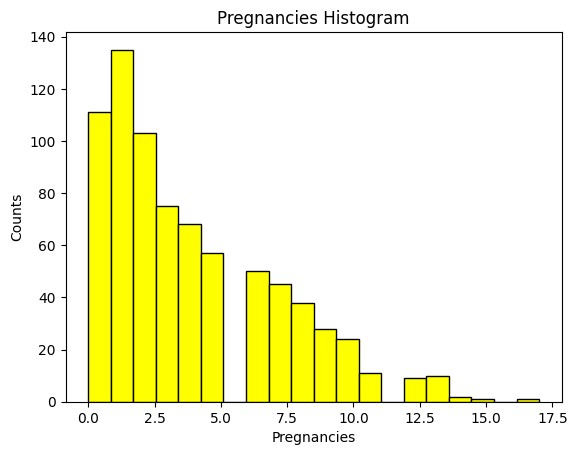

In [500]:
df['Pregnancies'].hist(bins=20, edgecolor='black',color='yellow')
plt.title('Pregnancies Histogram')
plt.xlabel('Pregnancies')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

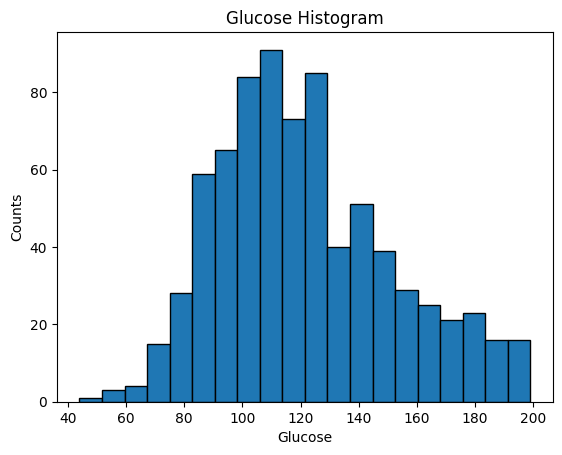

In [501]:
df['Glucose'].hist(bins=20, edgecolor='black')
plt.title('Glucose Histogram')
plt.xlabel('Glucose')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

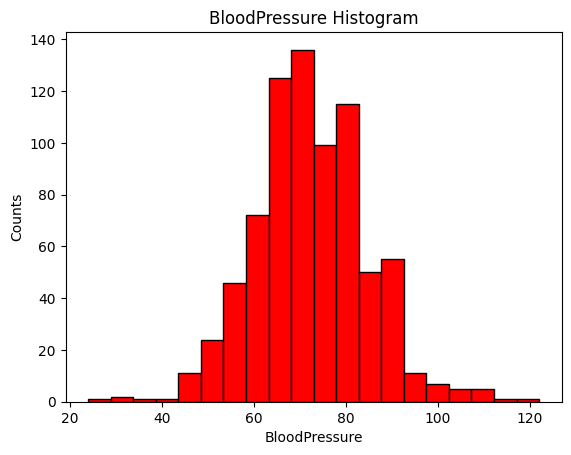

In [502]:
df['BloodPressure'].hist(bins=20, edgecolor='black',color='red')
plt.title('BloodPressure Histogram')
plt.xlabel('BloodPressure')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

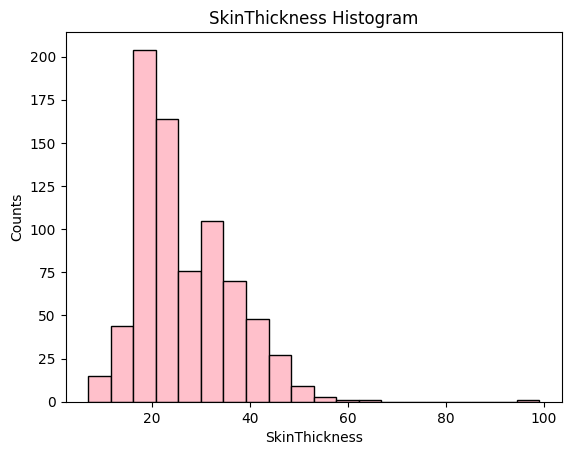

In [503]:
df['SkinThickness'].hist(bins=20, edgecolor='black',color='pink')
plt.title('SkinThickness Histogram')
plt.xlabel('SkinThickness')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

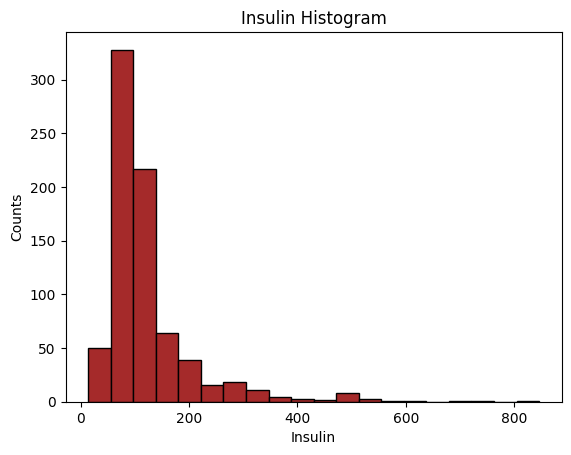

In [504]:
df['Insulin'].hist(bins=20, edgecolor='black',color='brown')
plt.title('Insulin Histogram')
plt.xlabel('Insulin')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

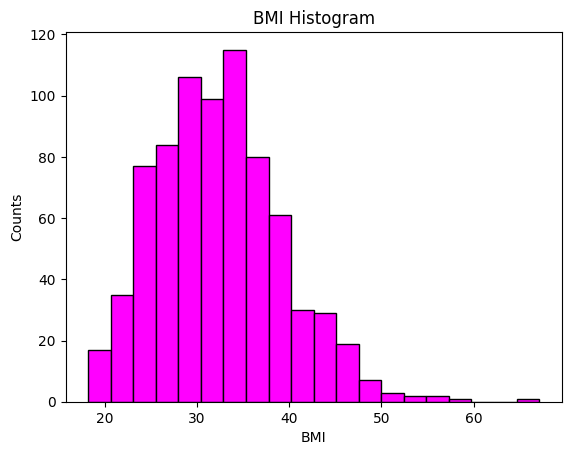

In [505]:
df['BMI'].hist(bins=20, edgecolor='black',color='magenta')
plt.title('BMI Histogram')
plt.xlabel('BMI')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

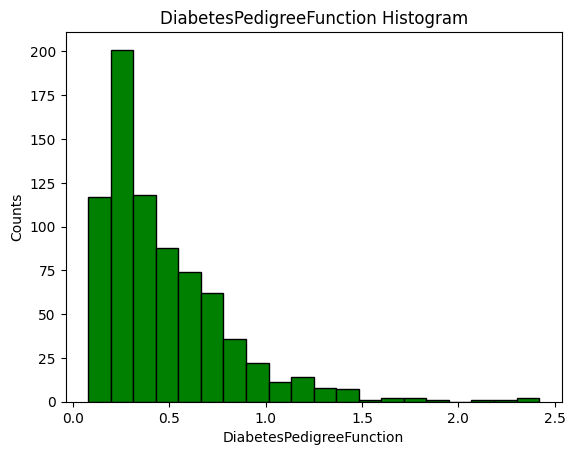

In [506]:
df['DiabetesPedigreeFunction'].hist(bins=20, edgecolor='black',color='green')
plt.title('DiabetesPedigreeFunction Histogram')
plt.xlabel('DiabetesPedigreeFunction')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

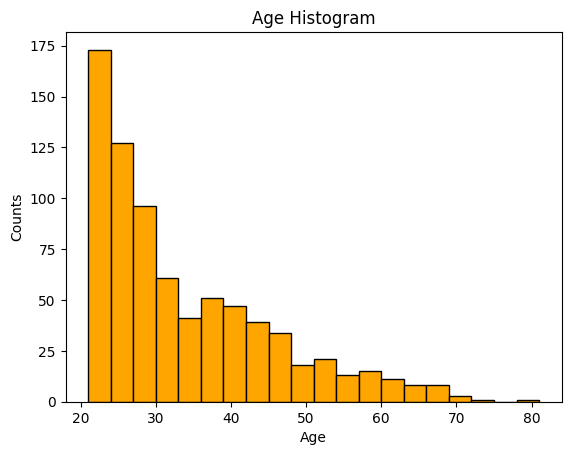

In [507]:
df['Age'].hist(bins=20, edgecolor='black',color='orange')
plt.title('Age Histogram')
plt.xlabel('Age')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

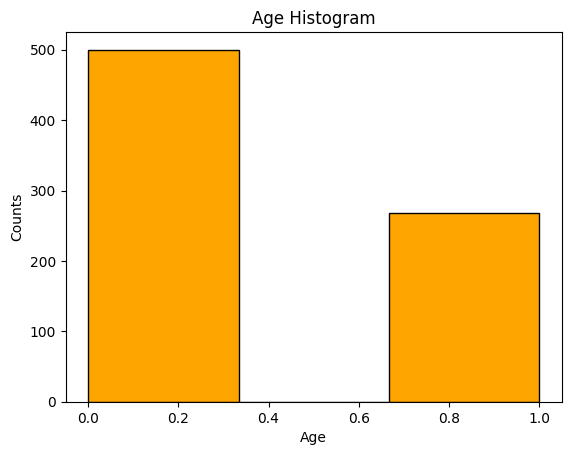

In [508]:
df['Outcome'].hist(bins=3, edgecolor='black',color='orange')
plt.title('Age Histogram')
plt.xlabel('Age')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

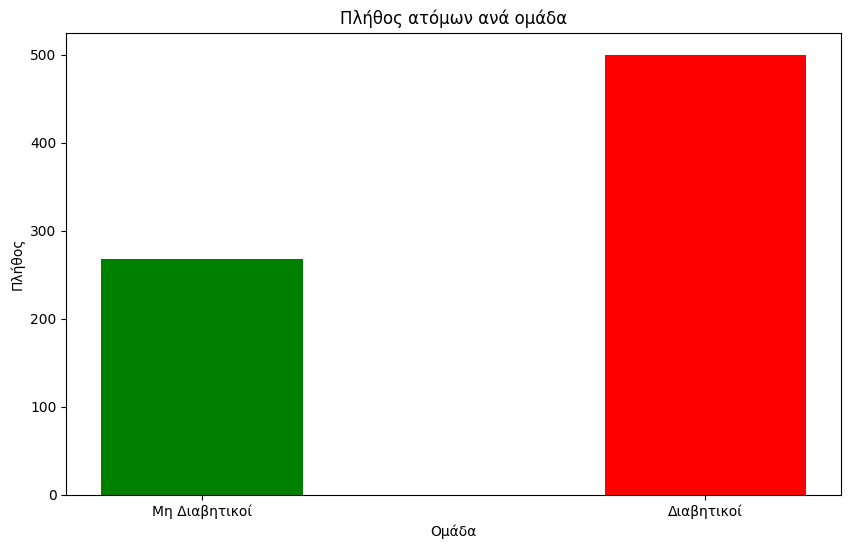

In [509]:
plt.figure(figsize=(10, 6))
x=[len(df[df['Outcome']==1]),len(df[df['Outcome']==0])]
y=["Μη Διαβητικοί","Διαβητικοί"]
plt.bar(y,x, color=["green","red"], width=0.4)
plt.xlabel("Ομάδα")
plt.ylabel("Πλήθος")
plt.title("Πλήθος ατόμων ανά ομάδα")
plt.show()


# Convert DataFrame to Numpy arrays

In [510]:
#Διαχωρισμός μεταβλητών
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']
x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((768, 8), (768,))

In [511]:
#Διαχωρισμός δεδομένων σε σύνολο εκπαίδεσης και επικύρωσης.
seed = 0
test_size = 0.3
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((537, 8), (537,), (231, 8), (231,))

# Split Dataset to Train-Test
Κατά την εκτέλεση του πραπάνω κώδικα, λαμβάνουμε τα παρακάτω αποτελέσματα ως προς τον διαχωρισμό των συνόλων.  

Train Samples: 537
Test Samples: 231
Seed: 0

# Create a Logistic Regression Model

In [512]:
#Δημιουργία μοντέλου λογιστικής παλινδρόμησης.
model= LogisticRegression(max_iter=5000, random_state=seed)

# Train model on training set

In [513]:
#Εκπαίδευση μοντέλου στο σύνολο εκπαίδευσης.
model.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=0)

# Evaluate Model on test set

In [514]:
#Πρόβλεψη του συνόλου επικύρωσης.
y_pred = model.predict(x_test)
y_pred

array([1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0])

In [515]:
#Ακρίβεια του μοντέλου ως προς το σύνολο επικύρωσης.
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)
print(f'The accuracy of the model for the test set is: {accuracy_percentage}')

The accuracy of the model for the test set is: 76.19


In [516]:
#Ακρίβεια του μοντέλου ως προς το σύνολο εκπαίδευσης.
y_pred_train=model.predict(x_train)
accuracy_train = accuracy_score(y_train, y_pred_train)
accuracy_train_percentage = round(accuracy_train*100, 2)
print(f'The accuracy of the model for train test is: {accuracy_train_percentage}')

The accuracy of the model for train test is: 77.28


Σύμφωνα με τα παραπαών αποτελέσματα έχουμε ότι :

*   Ακρίβεια Συνόλου Εκπαίδευσης: 77.28
*   Ακρίβεια Συνόλου Επικύρωσης: 76.19

Επομένως, η ακρίβεια του μοντέλου ως προς το σύνολο εκπαίδευσης είναι ελαφρώς μεγαλύτερη από του συνόλου επικύρωσης. Η σχέση αυτή είναι αναμενόμενη καθώς το μοντέλο στην πρώτη περίπτωση έχει εκπαιδευτεί πάνω στα δεδομένα που καλείται να προβλέψει. Ωστόσο, αξίζει να σημειώσουμε ότι η διαφορά μεταξύ της ακρίβειας μεταξύ των δύο συνόλων είναι ικανοποιητικά μικρή.

# Feature Importance

Retrain the model using standard scaling. Then, investigate coefficients. Larger coefficient values $\rightarrow$ more important features

## Data Scaling

In [517]:
#Scaling Δεδομένων
scaler = StandardScaler()
scaler.fit(x_train)

x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

## Model Training-Evaluation

In [518]:
#Επανεκπαίδευση μοντέλου με τα κανονικοποιημένα σύνολα και επαναλυπολογισμός της ακρίβειας πρόβλεψης
# στα σύνολα επικύρωσης και εκπαίδευσης.
model.fit(x_train, y_train)
y_pred= model.predict(x_test)
sc_accuracy = accuracy_score(y_test, y_pred)
sc_accuracy_percentage = round(accuracy*100, 2)
print(f'The accuracy of the model is: {sc_accuracy_percentage}')
y_pred_train = model.predict(x_train)
sc_accuracy_train= accuracy_score(y_train, y_pred_train)
sc_accuracy_train_percentage = round(sc_accuracy_train*100, 2)
print(f'The accuracy of the model is: {sc_accuracy_train_percentage}')

The accuracy of the model is: 76.19
The accuracy of the model is: 77.47


Παρατηρούμε ότι ενώ έχουμε κάνει scaling στα δεδομένα μας δεν παρατηρείται σημαντική μεταβολή στην ακρίβεια του μοντέλου. Ωστόσο, η επίδραση που έχει κάθε μεταβλητή στο μοντέλο παρουσιάζει μεταβολή. Αυτό συμβαίνει γιατί οι non-scaled μεταβλητές έχουν πολύ διαφορετικές κλίμακες.

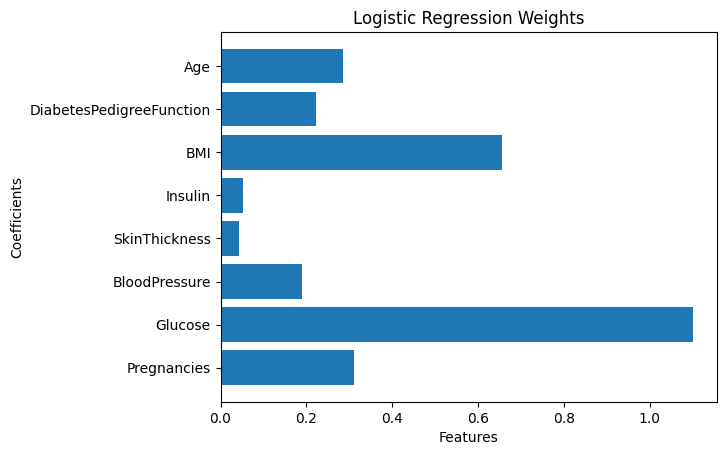

In [519]:
coeffs = model.coef_[0]
importance_weights = np.abs(coeffs)
plt.barh(input_df.columns, importance_weights)
plt.title('Logistic Regression Weights')
plt.xlabel('Features')
plt.ylabel('Coefficients')
plt.show()

Στο παραπάνω διάγραμμα φαίνεται η επίδραση που έχει κάθε μεταβλητή στο μοντέλο μας. Δηλαδή, όσο μεγαλύτερη είναι η (απόλυτη) τιμή του τόσο πιο πολύ επηρεάζεται την ταξινόμηση του ως προς την κατάλληλη κλάση. Όπως φαίνεται παραπάνω, η τιμή της Γλυκόζης έχει την μεγαλύτερη επίδραση και αυτό ***δικαιολογεί τη διαπίστωση ότι αν κάποιος ασθενής έχει υψηλά επίπεδα γλυκόζης, είναι πολύ πιθανό να εμφανίσει διαβήτη***.

# Διερεύνση Ηλικιακής Προσαρμογής

Σε αυτή την ενότητα θέλουμε να δούμε αν ο ταξινομητής μας δουλεύει καλά για όλες τις ηλικίες. Για να το διαπιστώουμε αυτό δημιουργούμε τρείς ηλικιακές κλάσεις στο σύνολο επικύρωσης.


*   Κλάση 1: Ηλικία από 0 εώς 25
*   Κλάση 2: Ηλικία από 25 εώς 50
*   Κλάση 3: Ηλικία μεγαλύτερη από 50


In [520]:
#Διαχωρισμός δεδομένων
#Καλούμε ξανά με το ίδιο seed τα σύνολα, προκειμένου να τα διαχωρίσουμε με βάση την ηλικία τους.
seed = 0
test_size = 0.3
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
#Βρίσκουμε ποιοι είναι οι δείκτες του x_test για τους οποίους ικανοποιείται η συγκεκριμένη συνθήκη.
group1=np.where(x_test[:, 7] < 25)[0]
#Από το x_test επιλέγουμε μόνο τις συγκεκριμένες τιμές και
# έπειτα μετασχηματίζουμε τα δεδομένα σύμφωνα με το scale που ορίσαμε προηγουμένως.
x_test_1=scaler.transform(x_test[group1])
#Επιλέγουμε τις αντίστοιχες εγγραφές από το y_test
y_test_1=y_test[group1]
#Ανάλογη διαδικασία κάνουμε και για τη δεύτερη κλάση.
group2=np.where((x_test[:,7]>=25)&(x_test[:,7]<50))[0]
x_test_2=scaler.transform(x_test[group2])
y_test_2=y_test[group2]
#Ανάλογη διαδικασία κάνουμε και για την τρίτη κλάση.
group3=np.where(x_test[:,7]>=50)[0]
x_test_3=scaler.transform(x_test[group3])
y_test_3=y_test[group3]
#Πρόβλεψη τιμών
y_pred_1=model.predict(x_test_1)
y_pred_2=model.predict(x_test_2)
y_pred_3=model.predict(x_test_3)

acc1=round(accuracy_score(y_pred_1,y_test_1)*100,2)
print(f'The accuracy of the model for the first class is: {acc1}')
acc2=round(accuracy_score(y_pred_2,y_test_2)*100,2)
print(f'The accuracy of the model for the second class is: {acc2}')
acc3=round(accuracy_score(y_pred_3,y_test_3)*100,2)
print(f'The accuracy of the model for the third class is: {acc3}')

The accuracy of the model for the first class is: 82.43
The accuracy of the model for the second class is: 70.68
The accuracy of the model for the third class is: 87.5


Επομένως, ο ταξινομητής ταξινομεί τα δεδομένα καλύτερα για τα άτομα που ανήκουν στην πρώτη (82%) και την τρίτη(87.5%) ηλικιακή ομάδα. Στη δεύτερη ηλικιακή ομάδα παρατηρούμε μια μικρή μείωση (70.7%). Το αποτέλεσμα παρουσιάζεται και στο παρακάτω ραβδόγραμμα.

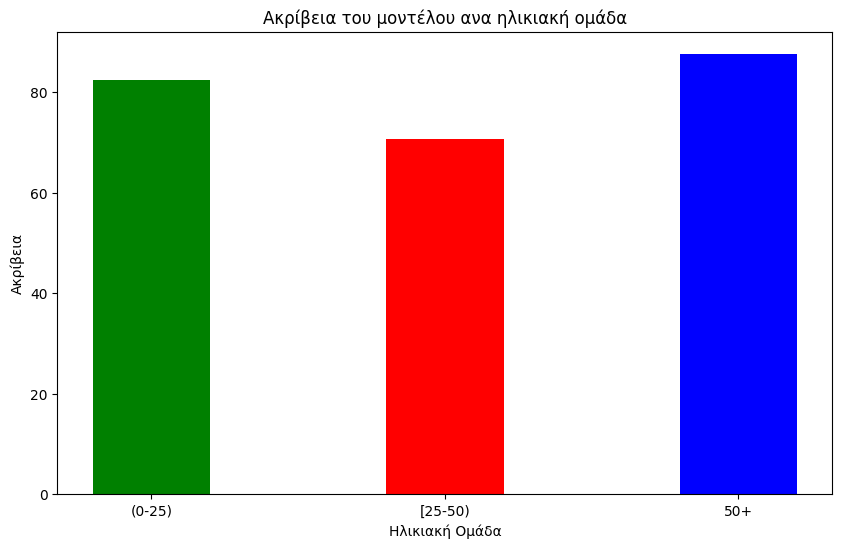

In [521]:
#Δημιουργία ραβδογράμματος
plt.figure(figsize=(10, 6))
x=[acc1,acc2,acc3]
y=["(0-25)","[25-50)","50+"]
plt.bar(y,x, color=["green","red","blue"], width=0.4)
plt.xlabel("Ηλικιακή Ομάδα")
plt.ylabel("Ακρίβεια")
plt.title("Ακρίβεια του μοντέλου ανα ηλικιακή ομάδα")
plt.show()

Για την συγκεκριμένη εφαρμογή, είναι προτιμότερο ο ταξινομητής να προβλέψει ότι κάποιος έχει διαβήτη ενώ στην πραγματικότητα δεν νοσεί.

Θεωρούμε έναν ασθενή, εάν η εφαρμογή προβλέψει ότι ο ασθενής έχει διαβήτη τότε ο ασθενής θα συμβουλευτεί τον γιατρό του προκειμένου να γίνουν οι απαραίτητες εξετάσεις. Ωστόσο, αν η εφαρμογή λανθασμένα προβλέψει ότι κάποιος δεν νοσεί θα τον αποτρέψει από τον προγραμματισμό μιας επίσκεψης.

Επομένως, είναι προτιμότερο να γίνει μια λανθασμένη πρόβλεψη ότι κάποιος νοσεί.

# Μέρος 2 – Γραμμική Παλινδρόμηση

Αρχικά, θα δημιουργήσουμε τα απαραίτητα σύνολα δεδομένων. Το γραμμικό μοντέλο θα έχει ως μεταβλητές δήλωσης τις **Εγκυμοσύνες**(Pregnancies), την **Ηλικία** (Age), το **Δείκτη Μάζας Σώματος** (BMI)  και την **Αρτηριακή Πίεση** (Blood Pressure), ενώ θα προβλέπει την τιμή **Γλυκόζη** (Glucose).

In [522]:
#Διαχωρισμός μεταβλητών-δημιουργία NumPy Arrays
input_df_lm = df.drop(columns=['Outcome','SkinThickness','Insulin','Glucose','DiabetesPedigreeFunction'])
targets_df_lm = df['Glucose']
x_lm= input_df_lm.to_numpy()
y_lm= targets_df_lm.to_numpy()
x_lm.shape, y_lm.shape

((768, 4), (768,))

In [523]:
#Διαχωρισμός δεδομένων σε σύνολο εκπαίδεσης και επικύρωσης.
seed = 0
test_size = 0.3
x_lm_train, x_lm_test, y_lm_train, y_lm_test = train_test_split(x_lm, y_lm, test_size=test_size, random_state=seed)
x_lm_train.shape, y_lm_train.shape, x_lm_test.shape, y_lm_test.shape

((537, 4), (537,), (231, 4), (231,))

In [524]:
#Εύρεση Μοντέλου Εκτός Βιβλιοθήκης
#ones=np.ones((len(x_lm_train),1))
#X=np.hstack((ones,x_lm_train))
#A=np.dot(X.T,X)
#det_A=np.linalg.det(A)
#inv_A=np.linalg.inv(A)
#W=np.dot(inv_A,X.T)
#W=np.dot(W,y_lm_train)
#W

In [525]:
#Δημιουργία μοντέλου γραμμικής παλινδρόμησης και εκπαίδευση.
model2=LinearRegression()
model2.fit(x_lm_train,y_lm_train)
y_lm_test_predict=model2.predict(x_lm_test)

In [526]:
#Σφάλματα
mse=np.round(mean_squared_error(y_lm_test,y_lm_test_predict),2)
mae=np.round(mean_absolute_error(y_lm_test,y_lm_test_predict),2)
rmse=np.round(np.sqrt(mse),2)#Τετραγωνική ρίζα του MSE
print(f' The mean squared error is : {mse} \n The mean absolute error is : {mae}')

 The mean squared error is : 876.4 
 The mean absolute error is : 22.85


Σύμφωνα με τα παραπάνω αποτελέσματα το μοντέλο που δημειουργείται από τις μεταβλητές:
* Εγκυμοσύνες(Pregnancies)
* Ηλικία (Age)
* Δείκτη Μάζας Σώματος (BMI)
* Αρτηριακή Πίεση (Blood Pressure)

εμφανίζει μέση απόλυτη απόκλιση κατα 22.85 (MAE) ενώ το μέσο τετραγωνικό σφάλμα(MSE) είναι 876.4. Επομένως,η τετραγωνική ρίζα του MSE είνια 29.6 (RMSE-Root MSE). Επειδή πρόκειται για την τιμή της γλυκόζης και οι λανθασμένες προβλέψεις μπορεί να αποτρέψουν τη διενέργεια περαιτέρω εξετάσεων, το MSE κρίνεται ως καταλληλότερος δείκτης αξιολόγησης.

# Αξιολόγηση Συντελεστών Μοντέλου

In [527]:
print(f'The coefficients of the model are : {model2.coef_} \nThe intercept of the model is :{model2.intercept_}')

The coefficients of the model are : [-0.12839155  0.19277656  1.08714063  0.70602769] 
The intercept of the model is :49.58514770381565


Παρατηρούμε ότι ορισμένες τιμές έχουν πολύ μικρό βάρος. Παρακάτω εξετάζουμε τη χρησιμότητα τους στο μοντέλο.

In [528]:
#Scaling για να έχουν τα δεδομένα μας την ίδια κλιμακα.
scaler.fit(x_lm_train)
x_lm_train=scaler.transform(x_lm_train)
x_lm_test=scaler.transform(x_lm_test)

model2.fit(x_lm_train,y_lm_train)
y_lm_test_predict=model2.predict(x_lm_test)
print(f'{model2.coef_} and {model2.intercept_}')

[-0.43677559  2.29680044  7.59340391  8.46688843] and 122.47946913477308


Παρατητούμε ότι μεταφέροντας τα δεδομένα σε ίδια κλίμακα οι συντελεστές των μεταβλητών μεταβάλονται. Επειδή υπάρχουν συντελεστές με μικρή τιμή, θα προχωρήσουμε σε ομαλοποίηση του μοντέλου για να διαπιστώσουμε τη χρησιμότητα τους.

In [529]:
#Κάνουμε L1 Ομαλοποίηση(Lasso)
lasso= linear_model.Lasso(alpha=0.21)
lasso.fit(x_lm_train,y_lm_train)
print(np.round(lasso.coef_,2))
print(np.round(lasso.intercept_,2))
y_lm_test_predict=lasso.predict(x_lm_test)
#Έλεγχος σφαλμάτων
mse=np.round(mean_squared_error(y_lm_test,y_lm_test_predict),2)
mae=np.round(mean_absolute_error(y_lm_test,y_lm_test_predict),2)
rmse=np.round(np.sqrt(mse),2)#Τετραγωνική ρίζα του MSE
print(f' The mean squared error is : {mse} \n The mean absolute error is : {mae}')

[-0.    2.18  7.43  8.06]
122.48
 The mean squared error is : 875.11 
 The mean absolute error is : 22.85


Σύμφωνα με τα παραπάνω αποτελέσματα η σημαντικότερη μεταβλητή για την πρόβλεψη της τιμής της γλυκόζης είναι η **Ηλικία**. Σημαντική είναι ακόμα και η μεταβλητή **ΔΜΣ** . Επιπλέον, στο αρχικό μας μοντέλο η μεταβλητή Εγκυμοσύνες δεν επηρεάζει σημαντικά το μοντέλο μας και μπορούμε να προχωρήσουμε στην αφαίρεση της. Η μεταβολή αυτή επηρεάζει-μειώνει σε μικρό βαθμό την τιμή MSE. Το μοντέλο για τον υπολογισμό της γλυκόζης είναι :



> Glucose= 2.18 * BloodPressure + 7.43 * BMI + 8.06 * Age + 122.48
